In [1]:
import os # Configure which GPU

if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    # gpu_num = 0 # Use "" to use the CPU
    # os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Import Sionna
try:
    import sionna
except ImportError as e:
    # Install Sionna if package is not already installed
    import os
    os.system("pip install sionna")
    import sionna

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

# Colab does currently not support the latest version of ipython.
# Thus, the preview does not work in Colab. However, whenever possible we
# strongly recommend to use the scene preview mode.
try: # detect if the notebook runs in Colab
    import google.colab
    no_preview = True # deactivate preview
except:
    if os.getenv("SIONNA_NO_PREVIEW"):
        no_preview = True
    else:
        no_preview = False

resolution = [480,320] # increase for higher quality of renderings

import matplotlib.pyplot as plt
import numpy as np
import time
import pandas as pd

# Set random seed for reproducibility

# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera, Paths

# For link-level simulations
from sionna.channel import cir_to_ofdm_channel, subcarrier_frequencies, OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.utils import compute_ber, ebnodb2no, PlotBER

from nr_pusch.model import Model, CIRGenerator, PUSCHModel
from nr_pusch.configs import SISOConfig, MIMOConfig

sionna.config.seed = 42
tf.random.set_seed(42)
np.random.seed(42)

In [3]:
# Define the number of samples per scenario and model type
num_samples_per_scenario = 2000

# Initialize the dataset
dataset = []


# Define the scenarios and Eb/No values
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19

model_types = ["tdl","cdl"]

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=2,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=4,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
# # System parameters
# subcarrier_spacing = 30e3
# num_time_steps = 14 # Total number of ofdm symbols per slot

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)
# # Loop through each model type
# for model_type in model_types:
#     # Loop through each scenario
#     for scenario in scenarios:
#         if model_type == "tdl":
#             model = Model(
#                 perfect_csi=False,
#                 detector=None,
#                 # config=siso_configuration,
#                 config = mimo_configuration,
#                 model_type=model_type,
#                 scenario=scenario,
#             )
#             # continue
#         else:
#             model = Model(
#                 perfect_csi=False,
#                 detector=None,
#                 config=mimo_configuration,
#                 # config=siso_configuration,
#                 model_type=model_type,
#                 scenario=scenario,
#             )
#         # Loop through the number of samples per scenario
#         for sample_idx in range(num_samples_per_scenario):
#             ebno_db = np.random.uniform(ebno_min, ebno_max)
#             print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for scenario {scenario} and model type {model_type}")

#             # Randomly select an Eb/No value (Monte Carlo sampling)

#             # Extract features (Simulation)
#             features = model.extract_features(ebno_db=ebno_db)
#             print(features["y"].shape)
#             # Add additional metadata
#             features["scenario"] = scenario
#             features["ebno_db"] = ebno_db
#             features["model_type"] = model_type
#             # print shape of features y here
#             if scenario == "A" or scenario == "B" or scenario == "C":
#                 features["label"] = "NLOS"
#             else:
#                 features["label"] = "LOS"
#             # Append the features to the dataset (Aggregation)
#             dataset.append(features)


In [4]:
num_samples_per_scenario = 1000
dataset_test = []
# Generate Eb/No values with a step size of 1000
ebno_values = np.linspace(ebno_min, ebno_max, num_samples_per_scenario)

# Loop through each model type
for model_type in model_types:
    # Loop through each scenario
    for scenario in scenarios:
        if model_type == "tdl":
            model = Model(
                perfect_csi=False,
                detector=None,
                # config=siso_configuration,
                config=mimo_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        else:
            model = Model(
                perfect_csi=False,
                detector=None,
                # config=mimo_configuration,
                # config=siso_configuration,
                config=mimo_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        # Loop through the number of samples per scenario
        for sample_idx, ebno_db in enumerate(ebno_values):
            print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for scenario {scenario} and model type {model_type}")

            # Extract features (Simulation)
            features = model.extract_features(ebno_db=ebno_db)
            print(features["y"].shape)
            print(features["y"])
            # Add additional metadata
            features["scenario"] = scenario
            features["ebno_db"] = ebno_db
            features["model_type"] = model_type
            if scenario in ["A", "B", "C"]:
                features["label"] = "NLOS"
            else:
                features["label"] = "LOS"
            # Append the features to the dataset (Aggregation)
            dataset_test.append(features)


Generating sample 1/1000 for scenario A and model type tdl
(1, 1, 4, 14, 192)
[[[[[-0.03649253+1.19032907e+00j  1.3860561 +1.11529279e+00j
      0.17656869-1.32943213e+00j ... -0.14650594+5.67931652e-01j
      0.41157585-8.10063660e-01j  0.46752447-3.66560668e-02j]
    [ 0.6036847 +2.42449355e+00j -0.46857554+1.20762408e-01j
      0.39181665-3.52880418e-01j ...  1.4393759 +9.33278024e-01j
      0.15337029+1.50796473e+00j  0.3994072 -3.46593186e-03j]
    [-0.06809056-1.36122704e+00j  0.30294538+4.73261684e-01j
      0.93047875-2.06113076e+00j ... -0.12988047-5.40075302e-01j
     -0.47313246-4.80311275e-01j  0.6112235 -3.12579691e-01j]
    ...
    [ 1.6179051 -9.91227746e-01j -0.8422951 +1.21156538e+00j
      0.38921404-4.59867179e-01j ... -1.3709754 -6.86262548e-01j
      0.2209898 +8.32092524e-01j -0.01727684+8.81175101e-01j]
    [ 1.7400314 -2.74961770e-01j  2.118704  +1.39100242e+00j
     -0.7878703 -1.05611181e+00j ... -0.98027503+1.87022015e-01j
      0.1459564 +2.70853285e-04j -0.

KeyboardInterrupt: 

In [ ]:
import h5py
import numpy as np
import pandas as pd
import json

# Function to convert non-serializable types to serializable types
def convert_to_serializable(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    elif isinstance(value, (np.float32, np.float64)):
        return float(value)
    elif isinstance(value, (np.int32, np.int64)):
        return int(value)
    elif isinstance(value, (np.complex64, np.complex128)):
        return [value.real, value.imag]
    elif isinstance(value, (np.bool_)):
        return bool(value)
    else:
        return str(value)

# Save the 'y' feature and additional features of the dataset to an HDF5 file
def save_features_to_hdf5(filename, dataset):
    with h5py.File(filename, 'w') as f:
        for i, features in enumerate(dataset):
            grp = f.create_group(str(i))
            if 'y' in features:
                grp.create_dataset('y', data=features['y'])
            if 'ebno_db' in features:
                grp.attrs['ebno_db'] = json.dumps(convert_to_serializable(features['ebno_db']))
            if 'model_type' in features:
                grp.attrs['model_type'] = features['model_type']
            if 'label' in features:
                grp.attrs['label'] = features['label']
            if 'scenario' in features:
                grp.attrs['scenario'] = features['scenario']

# Load the 'y' feature and additional features of the dataset from an HDF5 file
def load_features_from_hdf5(filename):
    dataset = []
    with h5py.File(filename, 'r') as f:
        for key in f.keys():
            grp = f[key]
            features = {}
            features['y'] = grp['y'][:]
            if 'ebno_db' in grp.attrs:
                features['ebno_db'] = json.loads(grp.attrs['ebno_db'])
            if 'model_type' in grp.attrs:
                features['model_type'] = grp.attrs['model_type']
            if 'label' in grp.attrs:
                features['label'] = grp.attrs['label']
            if 'scenario' in grp.attrs:
                features['scenario'] = grp.attrs['scenario']
            dataset.append(features)
    return dataset
# Convert the dataset to a pandas DataFrame
df = pd.DataFrame(dataset)
df.head()

# Save the dataset to a CSV file
df.to_csv("dataset_tdl_cdl_training_mimo.csv", index=False)
# # Save the dataset to a CSV file
df = pd.DataFrame(dataset_test)
df.to_csv("dataset_tdl_cdl_testing_mimo.csv", index=False)
# Example usage
# Save the features of the dataset
save_features_to_hdf5('dataset_tdl_cdl_mimo.h5', dataset)
save_features_to_hdf5('dataset_tdl_cdl_test_mimo.h5', dataset_test)
# Convert the dataset to a pandas DataFrame
# df = pd.DataFrame(dataset)
# df.head()

# # Save the dataset to a CSV file
# df.to_csv("dataset_tdl_cdl_training.csv", index=False)
# # Save the dataset to a CSV file
# df = pd.DataFrame(dataset_test)
# df.to_csv("dataset_tdl_cdl_testing.csv", index=False)
# # Example usage
# # Save the features of the dataset
# save_features_to_hdf5('dataset_tdl_cdl.h5', dataset)
# save_features_to_hdf5('dataset_tdl_cdl_test.h5', dataset_test)


In [5]:
# Define the number of samples per scenario and model type
num_samples_per_scenario = 2000

# Initialize the dataset
dataset = []


# Define the scenarios and Eb/No values
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19

model_types = ["tdl","cdl"]

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=2,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=4,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
# # System parameters
# subcarrier_spacing = 30e3
# num_time_steps = 14 # Total number of ofdm symbols per slot

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
     -3.0 | 2.3235e-01 | 1.0000e+00 |      579943 |     2496000 |          500 |         500 |        94.4 |reached max iter       
     -1.0 | 1.8131e-01 | 1.0000e+00 |      452562 |     2496000 |          500 |         500 |        61.9 |reached max iter       
      1.0 | 1.1523e-01 | 9.8800e-01 |      287613 |     2496000 |          494 |         500 |        61.7 |reached max iter       
      3.0 | 4.1242e-02 | 5.3000e-01 |      102940 |     2496000 |          265 |         500 |        61.6 |reached max iter       
      5.0 | 4.5765e-03 | 8.8000e-02 |       11423 |     2496000 |           44 |         500 |        61.8 |reached max iter       
      7.0 | 1.7869e-04 | 6.0000e-03 |         446 |     2496000 |            3 |     

KeyboardInterrupt: 

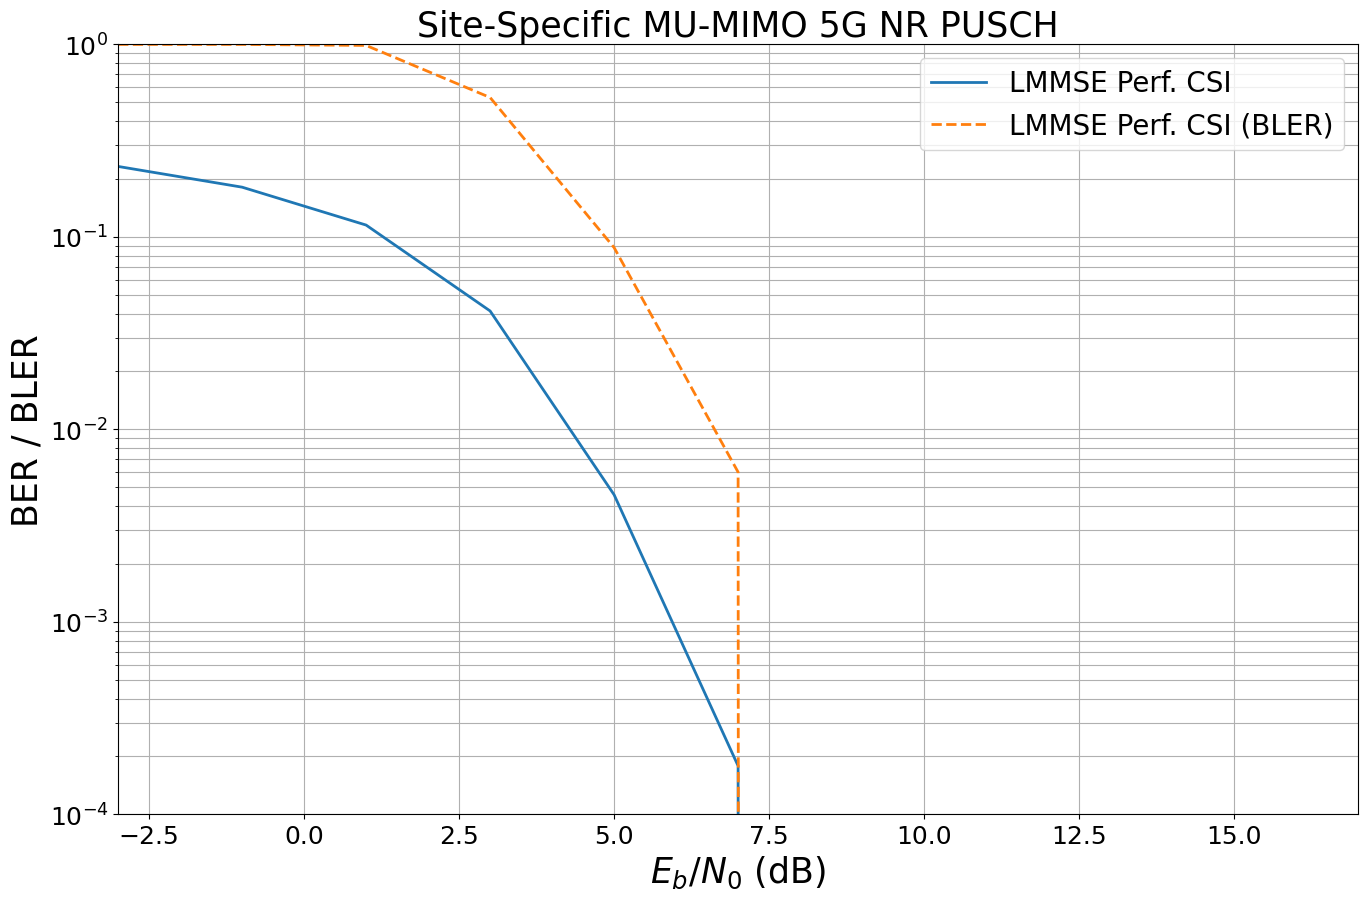

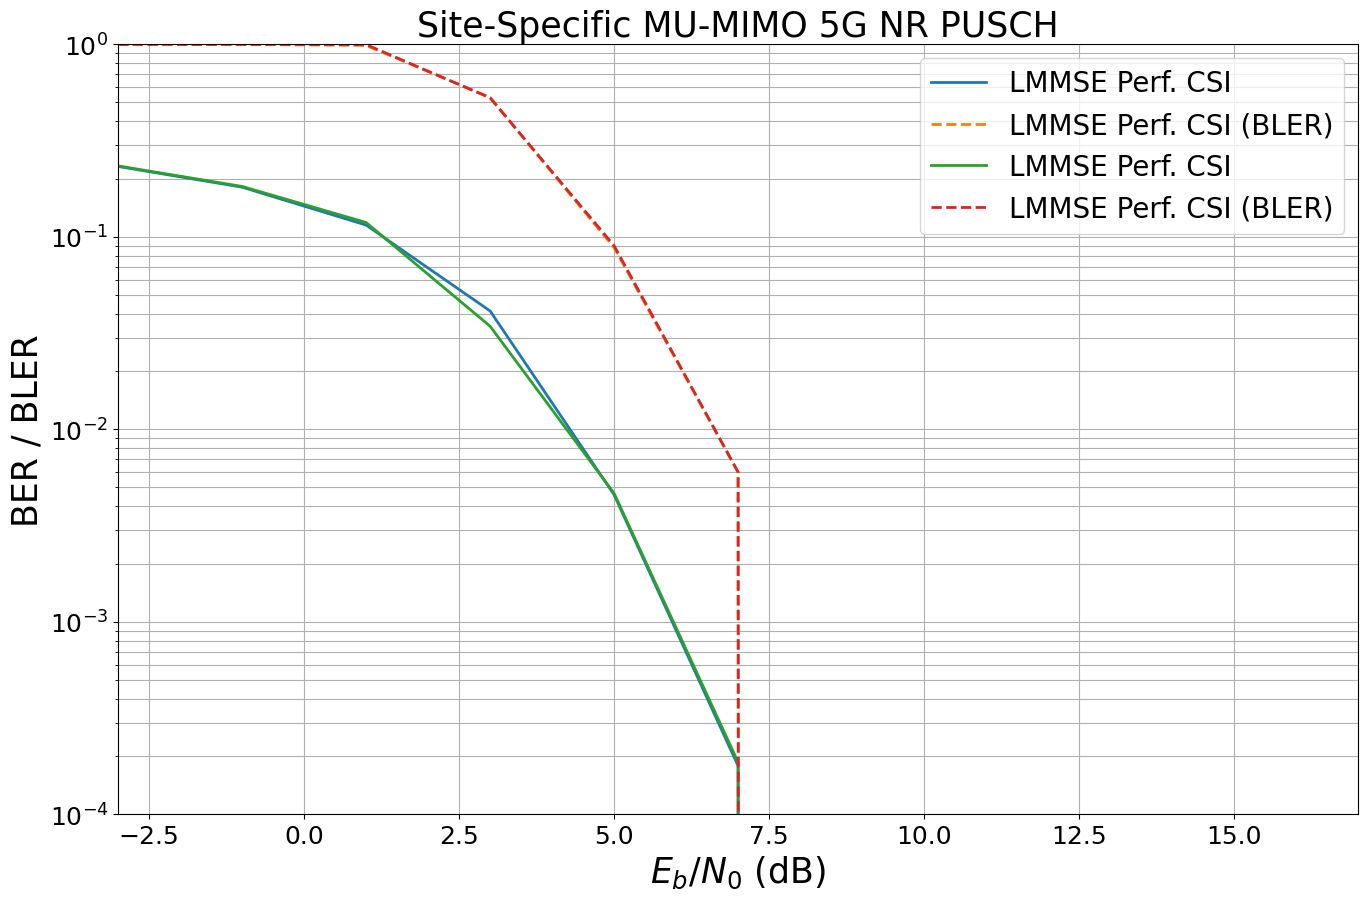

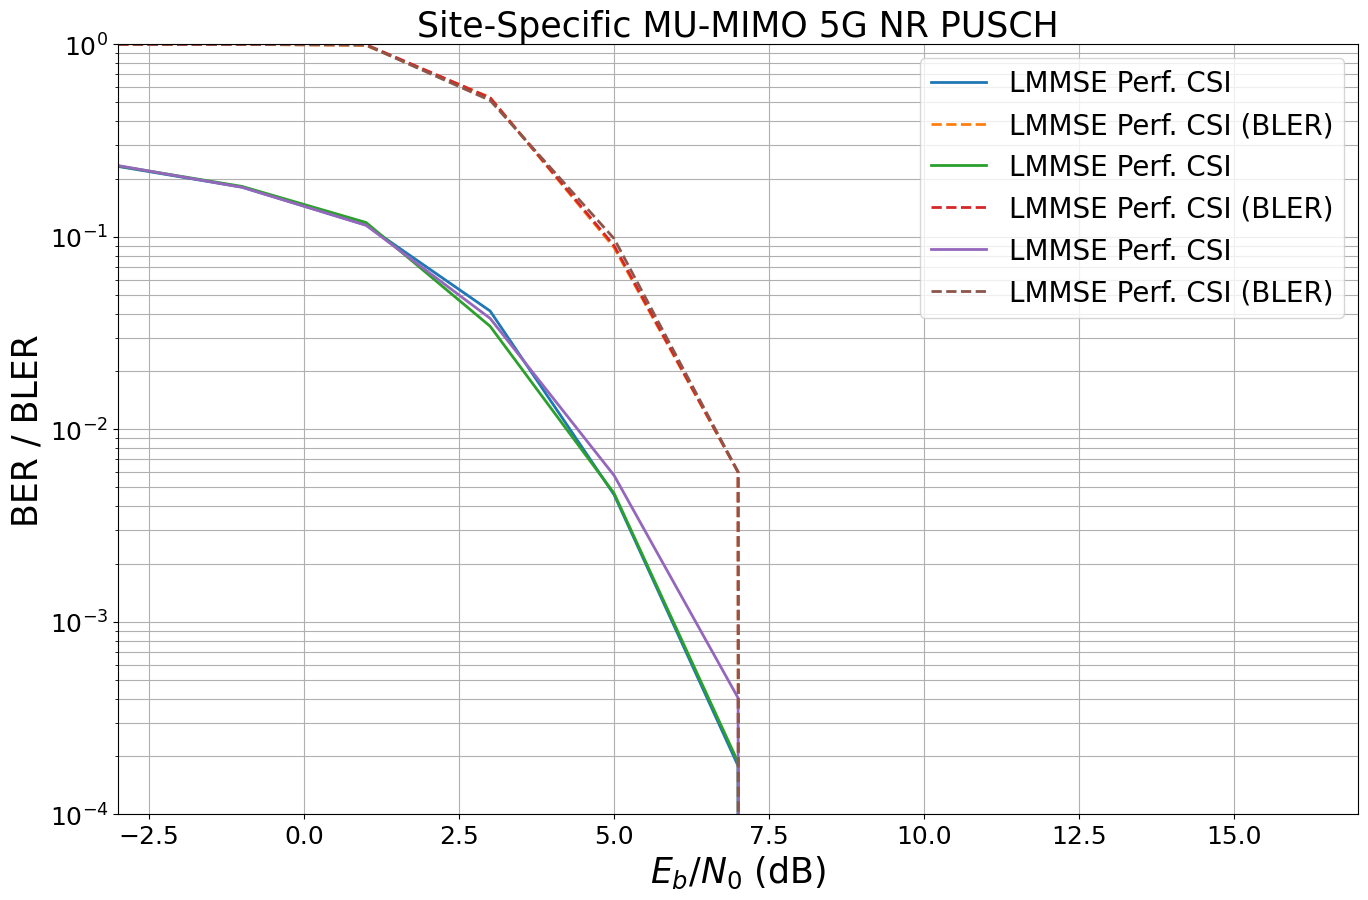

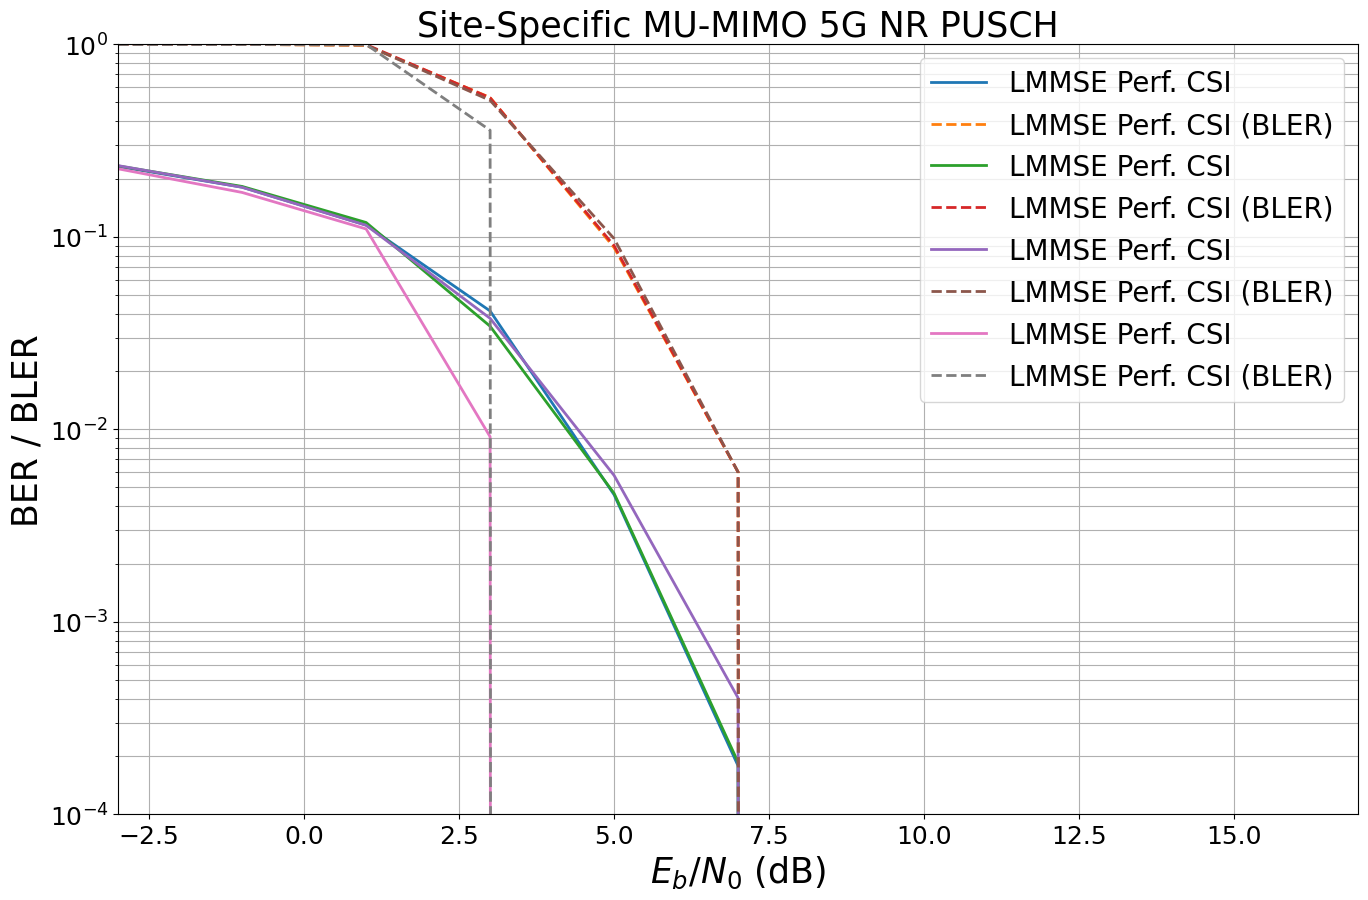

In [6]:
ebno_db = np.arange(-3, 18, 2) # sim SNR range
ber_plot = PlotBER(f"Site-Specific MU-MIMO 5G NR PUSCH")

for detector in ["lmmse", "kbest"]:
    for perf_csi in [True, False]:
        for model_type in model_types:
            # Loop through each scenario
            for scenario in scenarios:
                if model_type == "tdl":
                    model = Model(
                        perfect_csi=False,
                        detector=None,
                        # config=siso_configuration,
                        config = mimo_configuration,
                        model_type=model_type,
                        scenario=scenario,
                    )
                    # continue
                else:
                    model = Model(
                        perfect_csi=False,
                        detector=None,
                        config=mimo_configuration,
                        # config=siso_configuration,
                        model_type=model_type,
                        scenario=scenario,
                    )
                csi = "Perf. CSI" if perf_csi else "Imperf. CSI"
                det = "K-Best" if detector=="kbest" else "LMMSE"
                l = det + " " + csi
                ber_plot.simulate(
                            model,
                            ebno_dbs=ebno_db, # SNR to simulate
                            legend=l, # legend string for plotting
                            max_mc_iter=500,
                            num_target_block_errors=2000,
                            batch_size=siso_configuration.batch_size, # batch-size per Monte Carlo run
                            soft_estimates=False, # the model returns hard-estimates
                            early_stop=True,
                            show_fig=False,
                            add_bler=True,
                            forward_keyboard_interrupt=True);
                ber_plot(show_bler=True, show_ber=True, ylim=[1e-4,1], xlim=[-3,17])

In [10]:
ebno_db = np.arange(-3, 18, 2) # sim SNR range
ber_plot = PlotBER(f"Site-Specific MU-MIMO 5G NR PUSCH")
model_types = ["cdl"]
scenarios = ["A", "D"]
mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=2,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=4,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
for detector in ["lmmse", "kbest"]:
    for perf_csi in [True, False]:
        for model_type in model_types:
            # Loop through each scenario
            for scenario in scenarios:
                if model_type == "tdl":
                    model = Model(
                        perfect_csi=False,
                        detector=None,
                        # config=siso_configuration,
                        config = mimo_configuration,
                        model_type=model_type,
                        scenario=scenario,
                    )
                    # continue
                else:
                    model = Model(
                        perfect_csi=False,
                        detector=None,
                        config=mimo_configuration,
                        # config=siso_configuration,
                        model_type=model_type,
                        scenario=scenario,
                    )
                csi = "Perf. CSI" if perf_csi else "Imperf. CSI"
                det = "K-Best" if detector=="kbest" else "LMMSE"
                l = det + " " + csi
                ber_plot.simulate(
                            model,
                            ebno_dbs=ebno_db, # SNR to simulate
                            legend=l, # legend string for plotting
                            max_mc_iter=500,
                            num_target_block_errors=2000,
                            batch_size=siso_configuration.batch_size, # batch-size per Monte Carlo run
                            soft_estimates=False, # the model returns hard-estimates
                            early_stop=True,
                            show_fig=False,
                            add_bler=True,
                            forward_keyboard_interrupt=True);
            ber_plot(show_bler=True, show_ber=True, ylim=[1e-4,1], xlim=[-3,17])

KeyboardInterrupt: 

In [2]:
# SISO/MIMO/SIMO configs
# from nr_pusch.configs import SISOConfig, MIMOConfig

from sionna.mimo import StreamManagement
from sionna.ofdm import KBestDetector, LinearDetector
from sionna.utils import compute_ber, ebnodb2no
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.channel import OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.channel.tr38901 import CDL, TDL
from sionna.channel.tr38901 import AntennaArray, Antenna
import tensorflow as tf
import numpy as np

# Import Sionna RT components


class PUSCHModel(tf.keras.Model):
    def __init__(self, h_freq, ebno_db=2.0, batch_size=100):
        super().__init__()
        self.ebno_db = ebno_db
        self.batch_size = batch_size
        self.h_freq = h_freq  # Store h_freq as attribute
        # Simplified PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_transmitter = PUSCHTransmitter(self.pusch_config)
        self.pusch_receiver = PUSCHReceiver(self.pusch_transmitter)
        self.no = self.compute_noise()
        self.channel = ApplyOFDMChannel(add_awgn=True)

    def compute_noise(self):
        return ebnodb2no(
            self.ebno_db,
            self.pusch_transmitter._num_bits_per_symbol,
            self.pusch_transmitter._target_coderate,
            self.pusch_transmitter.resource_grid,
        )

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.pusch_transmitter(batch_size)
        y = self.channel([x, self.h_freq, self.no])
        b_hat = self.pusch_receiver([y, self.no])
        return b, b_hat

    def run(self):
        b, b_hat = self.call(self.batch_size, self.ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")


class PUSCHReceiverExtension:
    def __init__(
        self, config, detector, perfect_csi, transmitter
    ):  # Add transmitter as argument
        self.config = config
        self.perfect_csi = perfect_csi
        rx_tx_association = np.ones([1, config.num_tx], bool)
        stream_management = StreamManagement(rx_tx_association, config.num_layers)

        assert detector in [None, "lmmse", "kbest"], "Unsupported MIMO detector"
        if detector == None:
            self.detector = None
        elif detector == "lmmse":
            self.detector = LinearDetector(
                equalizer="lmmse",
                output="bit",
                demapping_method="maxlog",
                resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                stream_management=stream_management,
                constellation_type="qam",
                num_bits_per_symbol=config.create_pusch_configs()[
                    0
                ].tb.num_bits_per_symbol,
            )
        elif detector == "kbest":
            self.detector = KBestDetector(
                output="bit",
                num_streams=config.num_tx * config.num_layers,
                k=64,
                resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                stream_management=stream_management,
                constellation_type="qam",
                num_bits_per_symbol=config.create_pusch_configs()[
                    0
                ].tb.num_bits_per_symbol,
            )

        if self.perfect_csi:
            self.pusch_receiver = PUSCHReceiver(
                transmitter.pusch_transmitter,  # Use transmitter here
                mimo_detector=self.detector,
                input_domain=config.domain,
                channel_estimator="perfect",
                l_min=config.l_min if config.domain == "time" else None,
            )
        else:
            self.pusch_receiver = PUSCHReceiver(
                transmitter.pusch_transmitter,  # Use transmitter here
                mimo_detector=self.detector,
                input_domain=config.domain,
                l_min=config.l_min if config.domain == "time" else None,
            )


class Channel:
    def __init__(
        self,
        config,
        a,
        tau,
        model_type="",
        scenario="",
        channel_model=None,
    ):
        self.a = a
        self.tau = tau
        resource_grid = PUSCHTransmitterExtension(
            config
        ).pusch_transmitter.resource_grid

        # Check if model_type is valid
        assert model_type.lower() in ["cdl", "tdl", "sionna"], "Invalid model type"
        # self.channel_model = None
        if channel_model is None:
            if model_type.lower() == "cdl":
                # carrier_frequency = 2.14e9  # Carrier frequency in Hz.
                carrier_frequency = 3.5e9  # Carrier frequency in Hz.
                # This is needed here to define the antenna element spacing
                # Provide the missing arguments to PanelArray
                num_ut_ant = config.num_tx_ant
                num_bs_ant = config.num_rx_ant
                # Print the number of antennas
                # check if num_ut_ant and num_bs_ant are 1 or not
                if num_ut_ant != 1 and num_bs_ant != 1:
                    ut_array = AntennaArray(
                        num_rows=1,
                        num_cols=int(num_ut_ant / 2),
                        polarization="dual",
                        polarization_type="cross",
                        antenna_pattern="38.901",
                        carrier_frequency=carrier_frequency,
                    )
                    bs_array = AntennaArray(
                        num_rows=1,
                        num_cols=int(num_bs_ant / 2),
                        polarization="dual",
                        polarization_type="cross",
                        antenna_pattern="38.901",
                        carrier_frequency=carrier_frequency,
                    )
                else:
                    ut_array = AntennaArray(
                        num_rows=1,
                        num_cols=1,
                        antenna_pattern="38.901",
                        polarization="single",
                        polarization_type="V",
                        carrier_frequency=carrier_frequency,
                    )
                    bs_array = AntennaArray(
                        num_rows=1,
                        num_cols=1,
                        antenna_pattern="38.901",  # UE orientation is random
                        polarization="single",
                        polarization_type="V",
                        carrier_frequency=carrier_frequency,
                    )
                # Check if the scenario is valid, if not, setting the default as A with notice
                if scenario.upper() not in ["A", "B", "C", "D", "E"]:
                    print("Invalid scenario, defaulting to A")
                    scenario = "A"
                # Initialize the CDL model with the antenna arrays
                
                self.channel_model = CDL(
                    model=scenario.upper(),
                    ut_array=ut_array,  # Add ut_array
                    bs_array=bs_array,  # Add bs_array
                    delay_spread=300e-9, # rural,
                    carrier_frequency=3.5e9,
                    direction="uplink",
                    # direction="downlink",
                    min_speed=config.min_speed,
                    max_speed=config.max_speed,
                    # dopplershift = 0, delay spread 
                )
                self.a, self.tau = self.channel_model(
                    batch_size=config.batch_size,
                    num_time_steps=config.num_time_steps,
                    sampling_frequency=config.subcarrier_spacing,
                )
                print(f"CDL model initialized with scenario: {scenario}")
                print(f"Shape of a: {self.a.shape}")
                print(f"Shape of tau: {self.tau.shape}")
                print(f"Shape of a: {self.a.shape}")
                print(f"Shape of tau: {self.tau.shape}")
                # cir_generator = CIRGenerator(self.a, self.tau, config.num_tx, scenario)
                # self.channel_model = CIRDataset(
                #     cir_generator,
                #     config.batch_size,
                #     config.num_rx,
                #     config.num_rx_ant,
                #     config.num_tx,
                #     config.num_tx_ant,
                #     config.num_paths,
                #     config.num_time_steps,
                # )

                # print(f"ChannelModel: {self.channel_model.shape()}")
            elif model_type.lower() == "tdl":
                if scenario.upper() not in ["A", "B", "C", "D", "E"]:
                    print("Invalid scenario, defaulting to A")
                    scenario = "A"

                self.channel_model = TDL(
                    model=scenario.upper(),
                    num_rx_ant=config.num_rx_ant,
                    num_tx_ant=config.num_tx_ant,
                    delay_spread=300e-9,
                    carrier_frequency=3.5e9,
                    min_speed=config.min_speed,
                    max_speed=config.max_speed,
                )
                self.a, self.tau = self.channel_model(
                    batch_size=config.batch_size,
                    num_time_steps=config.num_time_steps,
                    sampling_frequency=config.subcarrier_spacing,
                )
                print(f"TDL model initialized with scenario: {scenario}")
                print(f"Shape of a: {self.a.shape}")
                print(f"Shape of tau: {self.tau.shape}")
                # cir_generator = CIRGenerator(self.a, self.tau, config.num_tx, scenario)

                # self.channel_model = CIRDataset(
                #     cir_generator,
                #     config.batch_size,
                #     config.num_rx,
                #     config.num_rx_ant,
                #     config.num_tx,
                #     config.num_tx_ant,
                #     config.num_paths,
                #     config.num_time_steps,
                # )

            elif model_type.lower() == "sionna":
                # Init CIR generator
                cir_generator = CIRGenerator(a, tau, config.num_tx, scenario)

                # Initialises a channel model that can be directly used by OFDMChannel layer
                self.channel_model = CIRDataset(
                    cir_generator,
                    config.batch_size,
                    config.num_rx,
                    config.num_rx_ant,
                    config.num_tx,
                    config.num_tx_ant,
                    # 12,
                    config.num_paths,
                    config.num_time_steps,
                )
        else:
            self.channel_model = channel_model
        self._channel = OFDMChannel(
            self.channel_model,
            resource_grid,
            normalize_channel=True,
            return_channel=True,
        )
        
    def __call__(self, inputs):
        y, self.h = self._channel(inputs)  # Store the CIR in self.h
        return y, self.h

    def return_a_tau(self):
        return self.a, self.tau


class CIRGenerator:
    """Creates a generator from a given dataset of channel impulse responses.

    The generator samples ``num_tx`` different transmitters from the given path
    coefficients `a` and path delays `tau` and stacks the CIRs into a single tensor.

    Note that the generator internally samples ``num_tx`` random transmitters
    from the dataset. For this, the inputs ``a`` and ``tau`` must be given for
    a single transmitter (i.e., ``num_tx`` =1) which will then be stacked
    internally.

    Parameters
    ----------
    a : [batch size, num_rx, num_rx_ant, 1, num_tx_ant, num_paths, num_time_steps], complex
        Path coefficients per transmitter.

    tau : [batch size, num_rx, 1, num_paths], float
        Path delays [s] per transmitter.

    num_tx : int
        Number of transmitters

    Output
    -------
    a : [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps], tf.complex
        Path coefficients

    tau : [batch size, num_rx, num_tx, num_paths], tf.float
        Path delays [s]
    """

    def __init__(self, a, tau, num_tx, scenario="siso"):

        # Copy to tensorflow
        self._a = tf.constant(a, tf.complex64)
        self._tau = tf.constant(tau, tf.float32)
        self._dataset_size = self._a.shape[0]

        self._num_tx = num_tx

        self._scenario = scenario

    def __call__(self):

        # Generator implements an infinite loop that yields new random samples
        while True:
            # Sample 4 random users and stack them together
            idx, _, _ = tf.random.uniform_candidate_sampler(
                tf.expand_dims(tf.range(self._dataset_size, dtype=tf.int64), axis=0),
                num_true=self._dataset_size,
                num_sampled=self._num_tx,
                unique=True,
                range_max=self._dataset_size,
            )

            a = tf.gather(self._a, idx)
            tau = tf.gather(self._tau, idx)

            # Transpose to remove batch dimension
            # if self._scenario.lower() == "mimo":
            a = tf.transpose(a, (3, 1, 2, 0, 4, 5, 6))
            tau = tf.transpose(tau, (2, 1, 0, 3))
            # And remove batch-dimension
            a = tf.squeeze(a, axis=0)
            tau = tf.squeeze(tau, axis=0)
            # print(f"Shape of a after going through CIRGenerator: {a.shape}")
            # print(f"Shape of tau after going through CIRGenerator: {tau.shape}")
            yield a, tau


class PUSCHTransmitterExtension:
    def __init__(self, config):
        self.config = config
        self.pusch_transmitter = PUSCHTransmitter(
            config.create_pusch_configs(), output_domain=config.domain
        )


class ChannelModel:
    def __init__(
        self,
        cir_generator,
        batch_size,
        num_rx,
        num_rx_ant,
        num_tx,
        num_tx_ant,
        num_paths,
        num_time_steps,
    ):
        self.cir_generator = cir_generator
        self.batch_size = batch_size
        self.num_rx = num_rx
        self.num_rx_ant = num_rx_ant
        self.num_tx = num_tx
        self.num_tx_ant = num_tx_ant
        self.num_paths = num_paths
        self.num_time_steps = num_time_steps

    # def __call__(self):
    def __call__(self):
        return self.cir_generator()

    def __len__(self):
        return self.batch_size


class Model(tf.keras.Model):
    def __init__(
        self,
        perfect_csi,
        detector,
        config,
        model_type="",
        scenario="",
        a=None,
        tau=None,
        paths=None,
        channel_model=None,
    ):
        super().__init__()
        self.config = config
        self.transmitter = PUSCHTransmitterExtension(self.config)
        self.receiver = PUSCHReceiverExtension(
            self.config, detector, perfect_csi, self.transmitter
        )
        
        self.a = a
        self.tau = tau
        if channel_model is not None:
            self.channel = Channel(
                self.config,
                self.a,
                self.tau,
                model_type,
                scenario,
                channel_model=channel_model,
            )
        else:
            self.channel = Channel(
                self.config,
                self.a,
                self.tau,
                model_type,
                scenario,
            )
        if a is None:
            # returns a, tau from channel model
            self.a, self.tau = self.channel.return_a_tau()
        self.model_type = model_type
        self.paths = paths



    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        self.x, self.b = self.transmitter.pusch_transmitter(self.config.batch_size)
        no = ebnodb2no(
            ebno_db,
            self.transmitter.pusch_transmitter._num_bits_per_symbol,
            self.transmitter.pusch_transmitter._target_coderate,
            self.transmitter.pusch_transmitter.resource_grid,
        )

        y, h = self.channel._channel([self.x, no])

        if self.receiver.perfect_csi:
            b_hat = self.receiver.pusch_receiver([y, h, no])
        else:
            b_hat = self.receiver.pusch_receiver([y, no])
        return self.b, b_hat

    @tf.function(jit_compile=False)
    def run(self, ebno_db):

        b, b_hat = self.call(self.config.batch_size, ebno_db)

        ber = compute_ber(b, b_hat)
        print(ber)
        print(f"BER: {ber.numpy()}")

    # @tf.function(jit_compile=False)
    # @tf.function
    def extract_features(self, ebno_db):
        paths = self.paths
        self.x, self.b = self.transmitter.pusch_transmitter(self.config.batch_size)
        no = ebnodb2no(
            ebno_db,
            self.transmitter.pusch_transmitter._num_bits_per_symbol,
            self.transmitter.pusch_transmitter._target_coderate,
            self.transmitter.pusch_transmitter.resource_grid,
        )
        # print(self.x.shape)
        y, h = self.channel([self.x, no])

        # Signal Power
        signal_power = tf.reduce_mean(tf.abs(y) ** 2)
        noise_power = tf.reduce_mean(tf.abs(no) ** 2)

        # Highest Power
        highest_power = tf.reduce_max(tf.abs(y) ** 2)

        # Kurtosis
        power = tf.abs(y) ** 2
        mean_power = tf.reduce_mean(power)
        kurtosis = tf.reduce_mean((power - mean_power) ** 4) / (
            tf.reduce_mean((power - mean_power) ** 2) ** 2
        )

        # Skewness
        skewness = tf.reduce_mean((power - mean_power) ** 3) / (
            tf.reduce_mean((power - mean_power) ** 2) ** 1.5
        )

        # CIR realizations
        t = self.tau[0, 0, 0, :] / 1e-9  # Scale to ns
        a_abs = np.abs(self.a)[0, 0, 0, 0, 0, :, 0] # This is beforee the channel model
        # print(a_abs.shape) # Shape description: [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
        # print(h.shape)     # Shape description: [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps]
        # print(y.shape)
        # plt.figure()
        # plt.title("Channel impulse response realization")
        # plt.stem(t, a_abs)
        # plt.xlabel(r"$\tau$ [ns]")
        # plt.ylabel(r"$|a|$")
        # plt.show()

        # plt.figure()
        # plt.title("Channel impulse response realization after channel model")
        # plt.stem(t, h_abs)
        # plt.xlabel(r"$\tau$ [ns]")
        # plt.ylabel(r"$|a|$")
        # plt.show()

        if self.model_type.lower() == "sionna":
            power = tf.abs(y) ** 2

            aoa = paths.theta_r
            aod = paths.theta_t
            zod = paths.phi_r
            zoa = paths.phi_t
            toa = self.tau

            # print(toa.shape)
            # print(power.shape)
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(toa_broadcasted * power_expanded) / tf.reduce_sum(power_expanded)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((toa_broadcasted - excess_mean_delay) ** 2 * power_expanded) / tf.reduce_sum(power_expanded))

            # Delay Spread
            mean_delay = tf.reduce_mean(paths.tau)
            delay_spread = tf.sqrt(tf.reduce_mean(tf.square(paths.tau - mean_delay)))

            # # Rician K-factor
            # los_mask = tf.expand_dims(paths.types == Paths.LOS, axis=-1)  # Expand dims to match power shape
            # nlos_mask = tf.expand_dims(~los_mask, axis=-1)  # Expand dims to match power shape
            # print(los_mask.shape)
            # print(nlos_mask.shape)
            # print(power.shape)
            # P_LOS = tf.reduce_sum(tf.abs(self.a) ** 2 * tf.cast(los_mask, tf.float32))
            # P_NLOS = tf.reduce_sum(tf.abs(paths.a) ** 2 * tf.cast(nlos_mask, tf.float32))

            # k_factor = P_LOS / P_NLOS if P_NLOS > 0 else tf.constant(0.0, dtype=tf.float32)
            k_factor = None
            # angular_spread = tf.reduce_mean(tf.abs(paths.a))
            # calculate angular spread based on the formula
            angular_spread = tf.reduce_mean(
                tf.sqrt(
                    (paths.theta_r - tf.reduce_mean(paths.theta_r)) ** 2
                    + (paths.phi_r - tf.reduce_mean(paths.phi_r)) ** 2
                )
            )

            # Mean direction of the Power angular spectrum
            power = tf.reshape(power, [-1])  # Flatten the power tensor if necessary
            theta_r = tf.reshape(
                paths.theta_r, [-1]
            )  # Flatten the theta_r tensor if necessary
            phi_r = tf.reshape(
                paths.phi_r, [-1]
            )  # Flatten the phi_r tensor if necessary

            min_length = min(
                tf.shape(power)[0], tf.shape(theta_r)[0], tf.shape(phi_r)[0]
            )
            power = power[:min_length]
            theta_r = theta_r[:min_length]
            phi_r = phi_r[:min_length]

            mean_theta_real = tf.reduce_sum(tf.cos(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta_imag = tf.reduce_sum(tf.sin(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta = tf.atan2(mean_theta_imag, mean_theta_real)

            mean_phi_real = tf.reduce_sum(tf.cos(phi_r) * power) / tf.reduce_sum(power)
            mean_phi_imag = tf.reduce_sum(tf.sin(phi_r) * power) / tf.reduce_sum(power)
            mean_phi = tf.atan2(mean_phi_imag, mean_phi_real)

            # Angular difference
            # angular_difference = tf.reduce_mean(
            #    tf.abs(tf.exp(1j * paths.theta_t) - tf.exp(1j * paths.theta_r))
            # )
            angular_difference = tf.reduce_mean(
                tf.abs(
                    tf.complex(tf.cos(paths.theta_t), tf.sin(paths.theta_t))
                    - tf.complex(tf.cos(paths.theta_r), tf.sin(paths.theta_r))
                )
            )

            # Ensure the shapes are compatible for matrix multiplication
            theta_r_reshaped = tf.reshape(paths.theta_r, [-1, 1])
            theta_t_reshaped = tf.reshape(paths.theta_t, [-1, 1])
            angular_variant = tf.reduce_sum(
                tf.linalg.eigvals(
                    tf.stack(
                        [
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                        ]
                    )
                )
            )

            doppler_shift = paths.doppler
        elif self.model_type.lower() == "tdl":
            aoa = None  # TDL model does not provide AoA
            aod = None  # TDL model does not provide AoD
            zod = None  # TDL model does not provide ZoD
            zoa = None  # TDL model does not provide ZoA
            toa = self.channel.channel_model.delays
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # rising_time = tf.reduce_mean(self.channel.channel_model.delays)
            delay_spread = self.channel.channel_model.delay_spread

            # # # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(tf.expand_dims(toa, axis=-1) * power) / tf.reduce_sum(power)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((tf.expand_dims(toa, axis=-1) - excess_mean_delay) ** 2 * power) / tf.reduce_sum(power))

            if self.channel.channel_model.los:
                k_factor = self.channel.channel_model.k_factor
            else:
                k_factor = None

            # Calculate Doppler shift
            batch_size = self.config.batch_size
            v_r = tf.random.uniform(
                shape=[batch_size, 1],
                minval=self.channel.channel_model._min_speed,
                maxval=self.channel.channel_model._max_speed,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_phi = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=2.0 * np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_theta = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            velocities = tf.stack(
                [
                    v_r * tf.cos(v_phi) * tf.sin(v_theta),
                    v_r * tf.sin(v_phi) * tf.sin(v_theta),
                    v_r * tf.cos(v_theta),
                ],
                axis=-1,
            )
            doppler_shift = tf.reduce_mean(tf.abs(velocities))

            # TDL model does not provide angular spread
            angular_spread = None
            mean_theta = None
            mean_phi = None
            angular_difference = None
            angular_variant = None
        elif self.model_type.lower() == "cdl":
            aoa = self.channel.channel_model._aoa
            aod = self.channel.channel_model._aod
            zod = self.channel.channel_model._zod
            zoa = self.channel.channel_model._zoa
            toa = self.channel.channel_model.delays
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # # # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(tf.expand_dims(toa, axis=-1) * power) / tf.reduce_sum(power)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((tf.expand_dims(toa, axis=-1) - excess_mean_delay) ** 2 * power) / tf.reduce_sum(power))

            # Delay Spread
            delay_spread = self.channel.channel_model.delay_spread

            if self.channel.channel_model.los:
                k_factor = self.channel.channel_model.k_factor
            else:
                k_factor = None

            angular_spread = (
                tf.reduce_mean(aoa)
                + tf.reduce_mean(aod)
                + tf.reduce_mean(zod)
                + tf.reduce_mean(zoa)
            ) / 4


            # Mean direction of the Power angular spectrum
            power = tf.reshape(power, [-1])  # Flatten the power tensor if necessary
            theta_r = tf.reshape(aoa, [-1])
            phi_r = tf.reshape(zoa, [-1])

            min_length = min(
                tf.shape(power)[0], tf.shape(theta_r)[0], tf.shape(phi_r)[0]
            )
            power = power[:min_length]
            theta_r = theta_r[:min_length]
            phi_r = phi_r[:min_length]

            mean_theta_real = tf.reduce_sum(tf.cos(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta_imag = tf.reduce_sum(tf.sin(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta = tf.atan2(mean_theta_imag, mean_theta_real)

            mean_phi_real = tf.reduce_sum(tf.cos(phi_r) * power) / tf.reduce_sum(power)
            mean_phi_imag = tf.reduce_sum(tf.sin(phi_r) * power) / tf.reduce_sum(power)
            mean_phi = tf.atan2(mean_phi_imag, mean_phi_real)

            angular_difference = tf.reduce_mean(
                tf.abs(
                    tf.complex(tf.cos(aod), tf.sin(aod))
                    - tf.complex(tf.cos(aoa), tf.sin(aoa))
                )
            )

            # Ensure the shapes are compatible for matrix multiplication
            theta_r_reshaped = tf.reshape(aoa, [-1, 1])
            theta_t_reshaped = tf.reshape(aod, [-1, 1])
            angular_variant = tf.reduce_sum(
                tf.linalg.eigvals(
                    tf.stack(
                        [
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                        ]
                    )
                )
            )

            batch_size = self.config.batch_size
            v_r = tf.random.uniform(
                shape=[batch_size, 1],
                minval=self.channel.channel_model._min_speed,
                maxval=self.channel.channel_model._max_speed,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_phi = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=2.0 * np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_theta = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            velocities = tf.stack(
                [
                    v_r * tf.cos(v_phi) * tf.sin(v_theta),
                    v_r * tf.sin(v_phi) * tf.sin(v_theta),
                    v_r * tf.cos(v_theta),
                ],
                axis=-1,
            )
            doppler_shift = tf.reduce_mean(tf.abs(velocities))
        features = {
            "y": safe_numpy(y),
            "h": safe_numpy(h),
            "a_abs": safe_numpy(a_abs),
            "t": safe_numpy(t),
            "snr": safe_numpy(
                10 * tf.math.log(signal_power / noise_power) / tf.math.log(10.0)
            ),
            "highest_received_power": safe_numpy(highest_power),
            "kurtosis": safe_numpy(kurtosis),
            "skewness": safe_numpy(skewness),
            "mean": safe_numpy(tf.reduce_mean(y)),
            "std": safe_numpy(tf.math.reduce_std(y)),
            "aoa": safe_numpy(aoa) if aoa is not None else aoa,
            "aod": safe_numpy(aod) if aod is not None else aod,
            "zoa": safe_numpy(zoa) if zoa is not None else zoa,
            "zod": safe_numpy(zod) if zod is not None else zod,
            "toa_prs": safe_numpy(toa),
            "rising_time": safe_numpy(rising_time),
            "delay_spread": safe_numpy(delay_spread),
            # "rms_delay_spread": safe_numpy(rms_delay_spread),
            "rician_k_factor": safe_numpy(k_factor),
            "angular_spread": (
                safe_numpy(angular_spread)
                if angular_spread is not None
                else angular_spread
            ),
            "mean_theta": (
                safe_numpy(mean_theta) if mean_theta is not None else mean_theta
            ),
            "mean_phi": safe_numpy(mean_phi) if mean_phi is not None else mean_phi,
            "angular_difference": (
                safe_numpy(angular_difference)
                if angular_difference is not None
                else angular_difference
            ),
            "angular_variant": (
                safe_numpy(angular_variant)
                if angular_variant is not None
                else angular_variant
            ),
            "doppler_shift": safe_numpy(doppler_shift),
            # "normalized_delay_power_correlation": safe_numpy(
            #     self.compute_normalized_delay_power_correlation(y, h)
            # ),
        }
        return features

    # @tf.function(jit_compile=False)
    def compute_normalized_delay_power_correlation(self, y, h):
        if self.model_type.lower() in ["cdl", "tdl"]:
            # For CDL and TDL models, use the channel model directly
            # print("Model type is CDL/TDL")
            # print(y.shape)
            # print(h.shape)
            y_tiled = tf.reshape(y, [-1])
            h_tiled = tf.reshape(h, [-1])
            # print(y_tiled.shape)
            # print(h_tiled.shape)
            # Ensure the shapes are compatible for broadcasting
            if y_tiled.shape[0] < h_tiled.shape[0]:
                h_tiled = h_tiled[: y_tiled.shape[0]]
            elif y_tiled.shape[0] > h_tiled.shape[0]:
                y_tiled = y_tiled[: h_tiled.shape[0]]
            correlation = tf.reduce_mean(y_tiled * tf.math.conj(h_tiled))
            return correlation.numpy()

        # For Sionna model
        # print("Model type is not CDL/TDL")
        y_expanded = y
        y_tiled = y_expanded
        # Check if SISO or MIMO to expand
        if self.config.num_tx != 1 or self.config.num_tx_ant != 1:
            if self.config.num_tx != 1:
                y_expanded = tf.expand_dims(y, axis=self.config.num_tx - 1)
            if self.config.num_tx_ant != 1:
                y_expanded = tf.expand_dims(y_expanded, axis=self.config.num_tx_ant)
                y_tiled = tf.tile(
                    y_expanded,
                    [1, 1, 1, self.config.num_tx, self.config.num_tx_ant, 1, 1],
                )
        else:
            y_tiled = y

        y_tiled = tf.reshape(y_tiled, [-1])
        h_tiled = tf.reshape(h, [-1])

        # Ensure the shapes are compatible for broadcasting
        if y_tiled.shape[0] < h_tiled.shape[0]:
            h_tiled = h_tiled[: y_tiled.shape[0]]
        elif y_tiled.shape[0] > h_tiled.shape[0]:
            y_tiled = y_tiled[: h_tiled.shape[0]]

        # Print shapes for debugging
        # print(f"Shape of y_tiled: {y_tiled.shape}")
        # print(f"Shape of h_tiled: {h_tiled.shape}")

        correlation = tf.reduce_mean(y_tiled * tf.math.conj(h_tiled))

        return correlation.numpy()

    def plot_cir_realization(self, a, tau):
        t = tau[0, 0, 0, :] / 1e-9  # Scale to ns
        a_abs = np.abs(a)[0, 0, 0, 0, 0, :, 0]
        a_max = np.max(a_abs)
        # Add dummy entry at start/end for nicer figure
        t = np.concatenate([(0.0,), t, (np.max(t) * 1.1,)])
        a_abs = np.concatenate([(np.nan,), a_abs, (np.nan,)])


def safe_numpy(tensor):
    try:
        return tensor.numpy()
    except:
        return tensor

In [ ]:
import h5py
import numpy as np
import pandas as pd
import json

# Function to convert non-serializable types to serializable types
def convert_to_serializable(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    elif isinstance(value, (np.float32, np.float64)):
        return float(value)
    elif isinstance(value, (np.int32, np.int64)):
        return int(value)
    elif isinstance(value, (np.complex64, np.complex128)):
        return [value.real, value.imag]
    elif isinstance(value, (np.bool_)):
        return bool(value)
    else:
        return str(value)

# Save the 'y' feature and additional features of the dataset to an HDF5 file
def save_features_to_hdf5(filename, dataset):
    with h5py.File(filename, 'w') as f:
        for i, features in enumerate(dataset):
            grp = f.create_group(str(i))
            if 'y' in features:
                grp.create_dataset('y', data=features['y'])
            if 'ebno_db' in features:
                grp.attrs['ebno_db'] = json.dumps(convert_to_serializable(features['ebno_db']))
            if 'model_type' in features:
                grp.attrs['model_type'] = features['model_type']
            if 'label' in features:
                grp.attrs['label'] = features['label']
            if 'scenario' in features:
                grp.attrs['scenario'] = features['scenario']
model_types = ["cdl"]
# Generate datasets for specific Eb/No values
specific_ebno_values = [0, 5, 10, 15]
# Define the number of samples per scenario and model type
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19

model_types = ["tdl","cdl"]

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=4,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=2,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
# # System parameters
# subcarrier_spacing = 30e3
# num_time_steps = 14 # Total number of ofdm symbols per slot

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)
datasets_by_ebno = {ebno: [] for ebno in specific_ebno_values}
num_samples_per_scenario = 1000
# Loop through each model type
for model_type in model_types:
    for scenario in scenarios:
        if model_type == "tdl":
            model = Model(
                perfect_csi=False,
                detector=None,
                config=mimo_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        else:
            model = Model(
                perfect_csi=False,
                detector=None,
                config=mimo_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        # for sample_idx, ebno_db in enumerate(ebno_values):
        #     if ebno_db in specific_ebno_values:
        for ebno_db in specific_ebno_values:
            for sample_idx in range(num_samples_per_scenario):
                print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for scenario {scenario}, model type {model_type}, and Eb/No {ebno_db} dB")
                features = model.extract_features(ebno_db=ebno_db)
                features["scenario"] = scenario
                features["ebno_db"] = ebno_db
                features["model_type"] = model_type
                features["label"] = "NLOS" if scenario in ["A", "B", "C"] else "LOS"
                datasets_by_ebno[ebno_db].append(features)
                # print(features["y"])
# Save datasets for each Eb/No value
for ebno, dataset in datasets_by_ebno.items():
    filename_csv = f"dataset_tdl_cdl_{ebno}db_mimo.csv"
    filename_h5 = f"dataset_tdl_cdl_{ebno}db_mimo.h5"
    df = pd.DataFrame(dataset)
    df.to_csv(filename_csv, index=False)
    save_features_to_hdf5(filename_h5, dataset)
    print(f"Saved dataset for {ebno} dB to {filename_csv} and {filename_h5}")

Generating sample 1/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 2/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 3/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 4/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 5/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 6/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 7/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 8/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 9/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 10/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 11/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 12/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 13/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 14/1000 for scenario A, model type tdl, an

KeyboardInterrupt: 

In [5]:
import h5py
import numpy as np
import pandas as pd
import json

# Function to convert non-serializable types to serializable types
def convert_to_serializable(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    elif isinstance(value, (np.float32, np.float64)):
        return float(value)
    elif isinstance(value, (np.int32, np.int64)):
        return int(value)
    elif isinstance(value, (np.complex64, np.complex128)):
        return [value.real, value.imag]
    elif isinstance(value, (np.bool_)):
        return bool(value)
    else:
        return str(value)

# Save the 'y' feature and additional features of the dataset to an HDF5 file
def save_features_to_hdf5(filename, dataset):
    with h5py.File(filename, 'w') as f:
        for i, features in enumerate(dataset):
            grp = f.create_group(str(i))
            if 'y' in features:
                grp.create_dataset('y', data=features['y'])
            if 'ebno_db' in features:
                grp.attrs['ebno_db'] = json.dumps(convert_to_serializable(features['ebno_db']))
            if 'model_type' in features:
                grp.attrs['model_type'] = features['model_type']
            if 'label' in features:
                grp.attrs['label'] = features['label']
            if 'scenario' in features:
                grp.attrs['scenario'] = features['scenario']
model_types = ["cdl"]
# Generate datasets for specific Eb/No values
specific_ebno_values = [0, 5, 10, 15]
# Define the number of samples per scenario and model type
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19

model_types = ["tdl","cdl"]

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=4,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=2,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
# # System parameters
# subcarrier_spacing = 30e3
# num_time_steps = 14 # Total number of ofdm symbols per slot

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)
datasets_by_ebno = {ebno: [] for ebno in specific_ebno_values}
num_samples_per_scenario = 1000
# Loop through each model type
for model_type in model_types:
    for scenario in scenarios:
        if model_type == "tdl":
            model = Model(
                perfect_csi=False,
                detector=None,
                config=siso_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        else:
            model = Model(
                perfect_csi=False,
                detector=None,
                config=siso_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        # for sample_idx, ebno_db in enumerate(ebno_values):
        #     if ebno_db in specific_ebno_values:
        for ebno_db in specific_ebno_values:
            for sample_idx in range(num_samples_per_scenario):
                print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for scenario {scenario}, model type {model_type}, and Eb/No {ebno_db} dB")
                features = model.extract_features(ebno_db=ebno_db)
                features["scenario"] = scenario
                features["ebno_db"] = ebno_db
                features["model_type"] = model_type
                features["label"] = "NLOS" if scenario in ["A", "B", "C"] else "LOS"
                datasets_by_ebno[ebno_db].append(features)
                # print(features["y"])
# Save datasets for each Eb/No value
for ebno, dataset in datasets_by_ebno.items():
    # filename_csv = f"dataset_tdl_cdl_{ebno}db_mimo.csv"
    # filename_h5 = f"dataset_tdl_cdl_{ebno}db_mimo.h5"
    filename_csv = f"dataset_tdl_cdl_{ebno}db_siso.csv"
    filename_h5 = f"dataset_tdl_cdl_{ebno}db_siso.h5"
    df = pd.DataFrame(dataset)
    df.to_csv(filename_csv, index=False)
    save_features_to_hdf5(filename_h5, dataset)
    print(f"Saved dataset for {ebno} dB to {filename_csv} and {filename_h5}")

TDL model initialized with scenario: A
Shape of a: (1, 1, 1, 1, 1, 23, 14)
Shape of tau: (1, 1, 1, 23)
Generating sample 1/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 2/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 3/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 4/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 5/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 6/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 7/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 8/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 9/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 10/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 11/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 12/1000 for scenario A, model type tdl, and Eb/No 0 dB
Generating sample 13/1000 for 

In [6]:
import numpy as np
import matplotlib.pyplot as plt
# Define the number of samples per scenario and model type
num_samples_per_scenario = 2000

# Initialize the dataset
dataset = []


# Define the scenarios and Eb/No values
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19

model_types = ["tdl","cdl"]

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=1,
    num_tx=1,
    subcarrier_spacing= 15e3,
    num_rx_ant=1,
    num_rx=1,
    num_symbols=14,
    batch_size= 1,
    min_speed = 0,
    max_speed = 10
)
# # System parameters
# subcarrier_spacing = 30e3
# num_time_steps = 14 # Total number of ofdm symbols per slot

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)
siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=1,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_layers=1,
    min_speed = 0,
    max_speed = 10
)

# Settings
ebno_values_small = [35, 45, 55, 6500]
scenarios = ["A", "B", "C", "D", "E"]
model_types = ["tdl", "cdl"]
dataset_test_small = []

# Generate 1 sample for each (model_type, scenario, ebno)
for model_type in model_types:
    for scenario in scenarios:
        model = Model(
            perfect_csi=False,
            detector=None,
            config=siso_configuration,
            model_type=model_type,
            scenario=scenario,
        )
        for ebno_db in ebno_values_small:
            print(f"Generating for scenario {scenario}, model type {model_type}, Eb/No {ebno_db} dB")
            features = model.extract_features(ebno_db=ebno_db)
            features["scenario"] = scenario
            features["ebno_db"] = ebno_db
            features["model_type"] = model_type
            features["label"] = "NLOS" if scenario in ["A", "B", "C"] else "LOS"
            dataset_test_small.append(features)
            print("y shape:", features["y"].shape)

print(f"Total samples generated: {len(dataset_test_small)}")

# ---- Plotting ----
pilot_symbols = [2, 11]


Generating for scenario A, model type tdl, Eb/No 35 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario A, model type tdl, Eb/No 45 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario A, model type tdl, Eb/No 55 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario A, model type tdl, Eb/No 6500 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario B, model type tdl, Eb/No 35 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario B, model type tdl, Eb/No 45 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario B, model type tdl, Eb/No 55 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario B, model type tdl, Eb/No 6500 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario C, model type tdl, Eb/No 35 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario C, model type tdl, Eb/No 45 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario C, model type tdl, Eb/No 55 dB
y shape: (1, 1, 1, 14, 192)
Generating for scenario C, model type tdl, Eb/No 6500 dB
y shape: (1, 1, 1, 14, 192

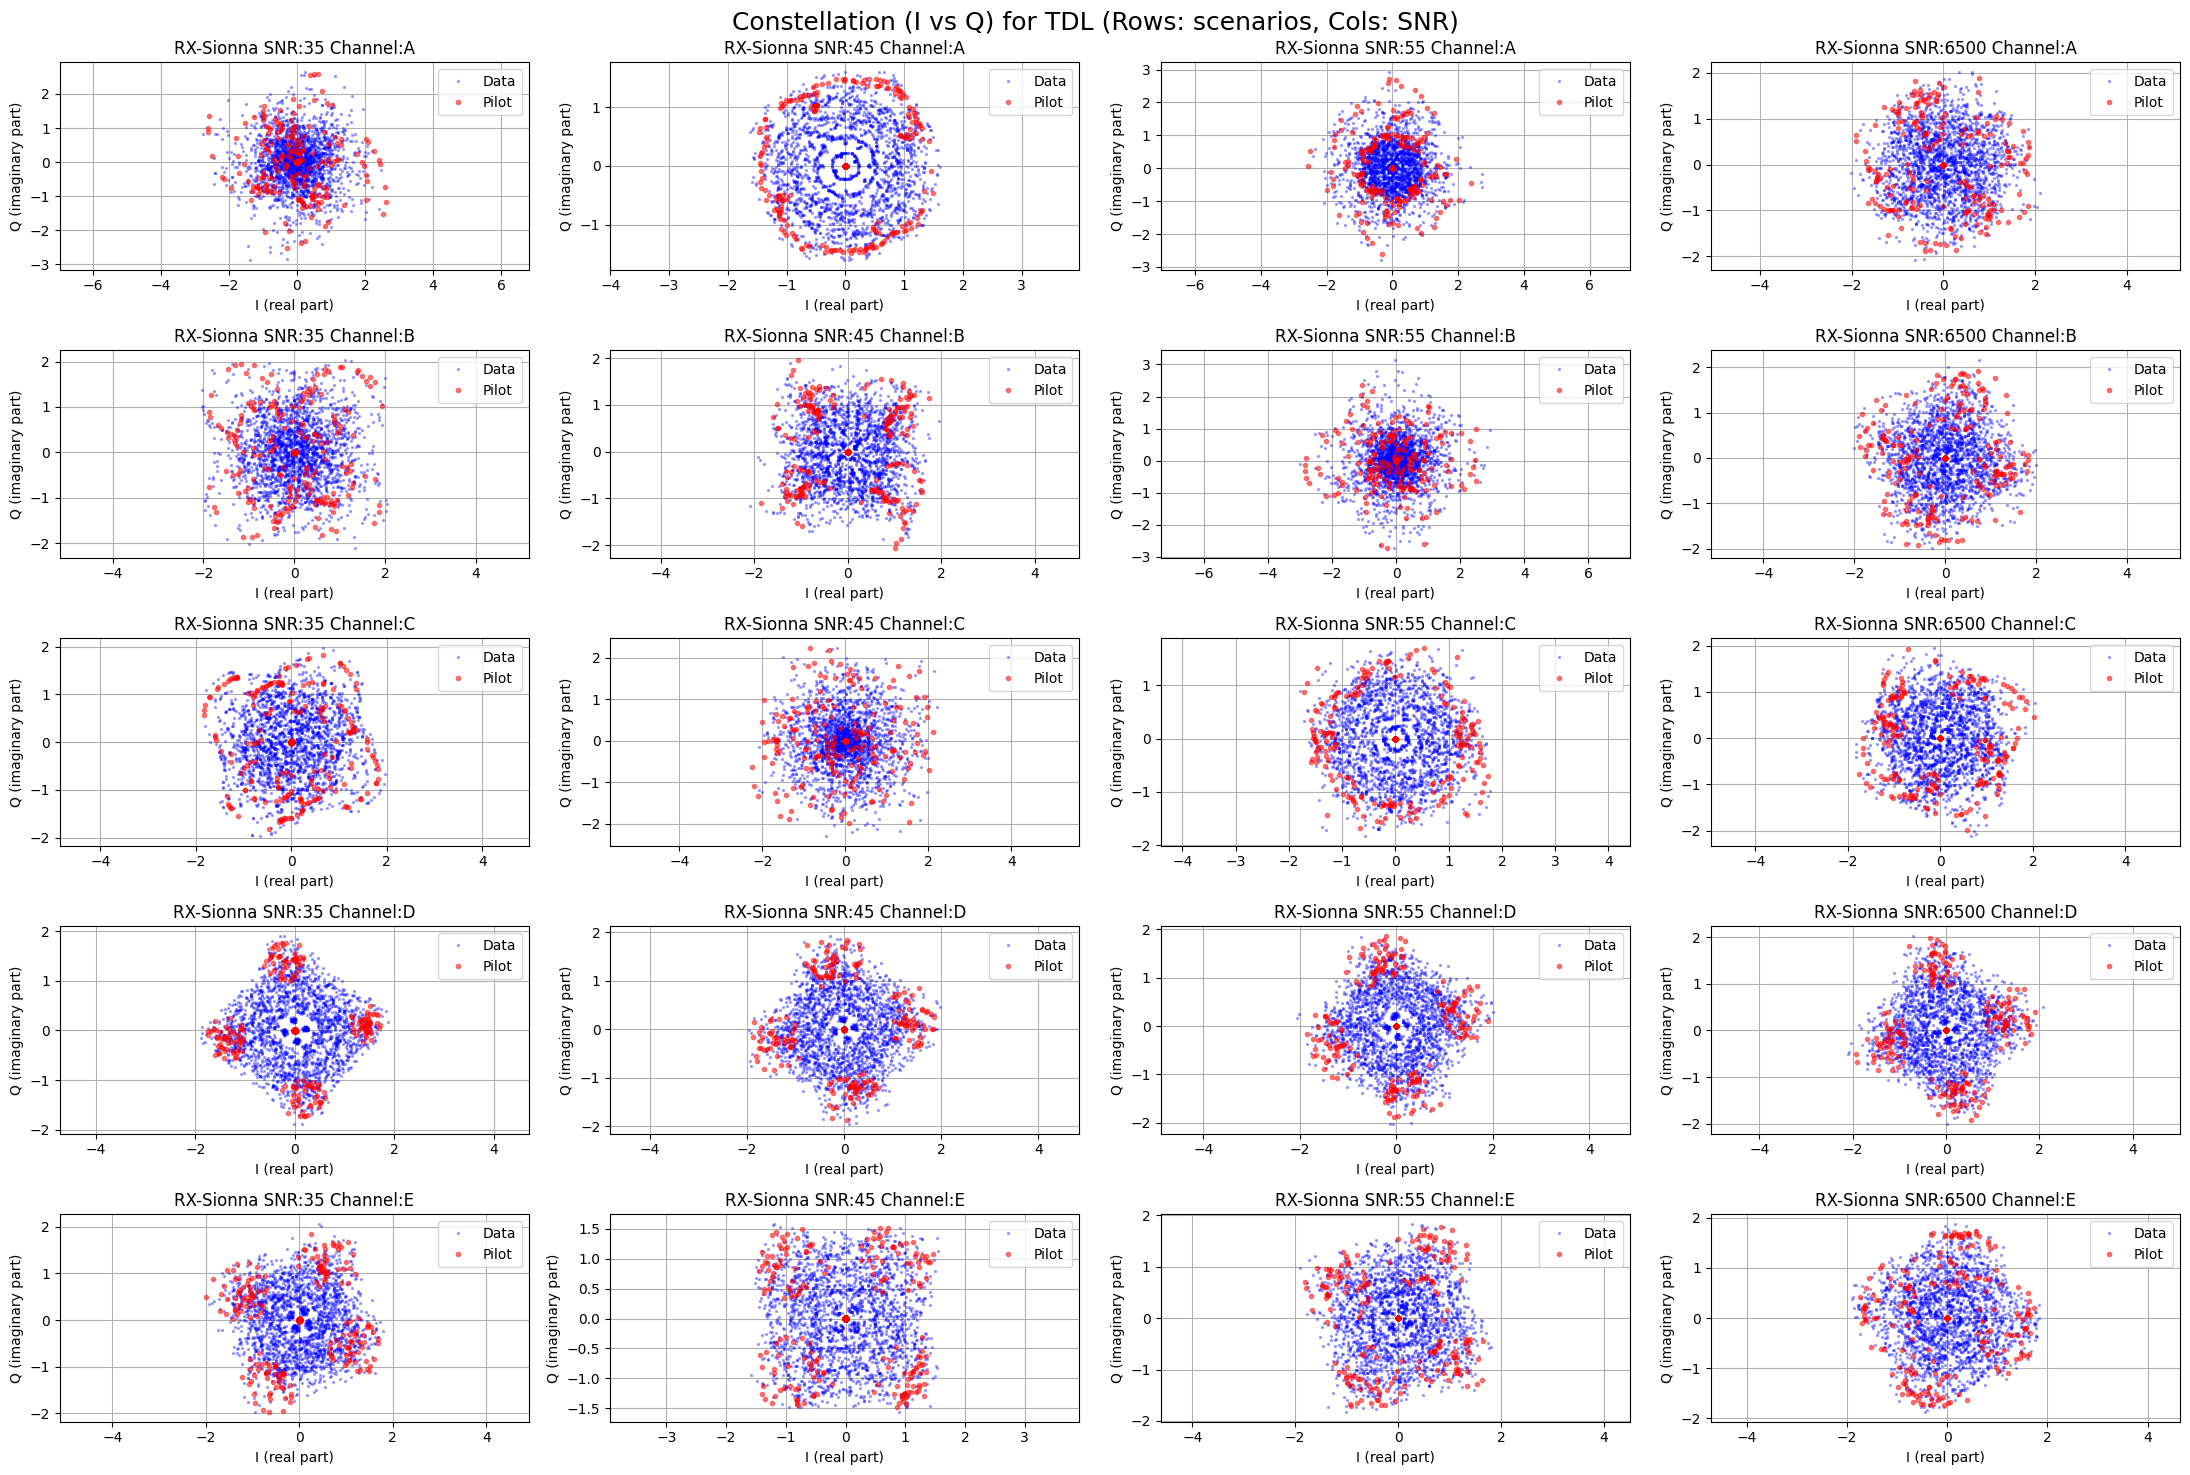

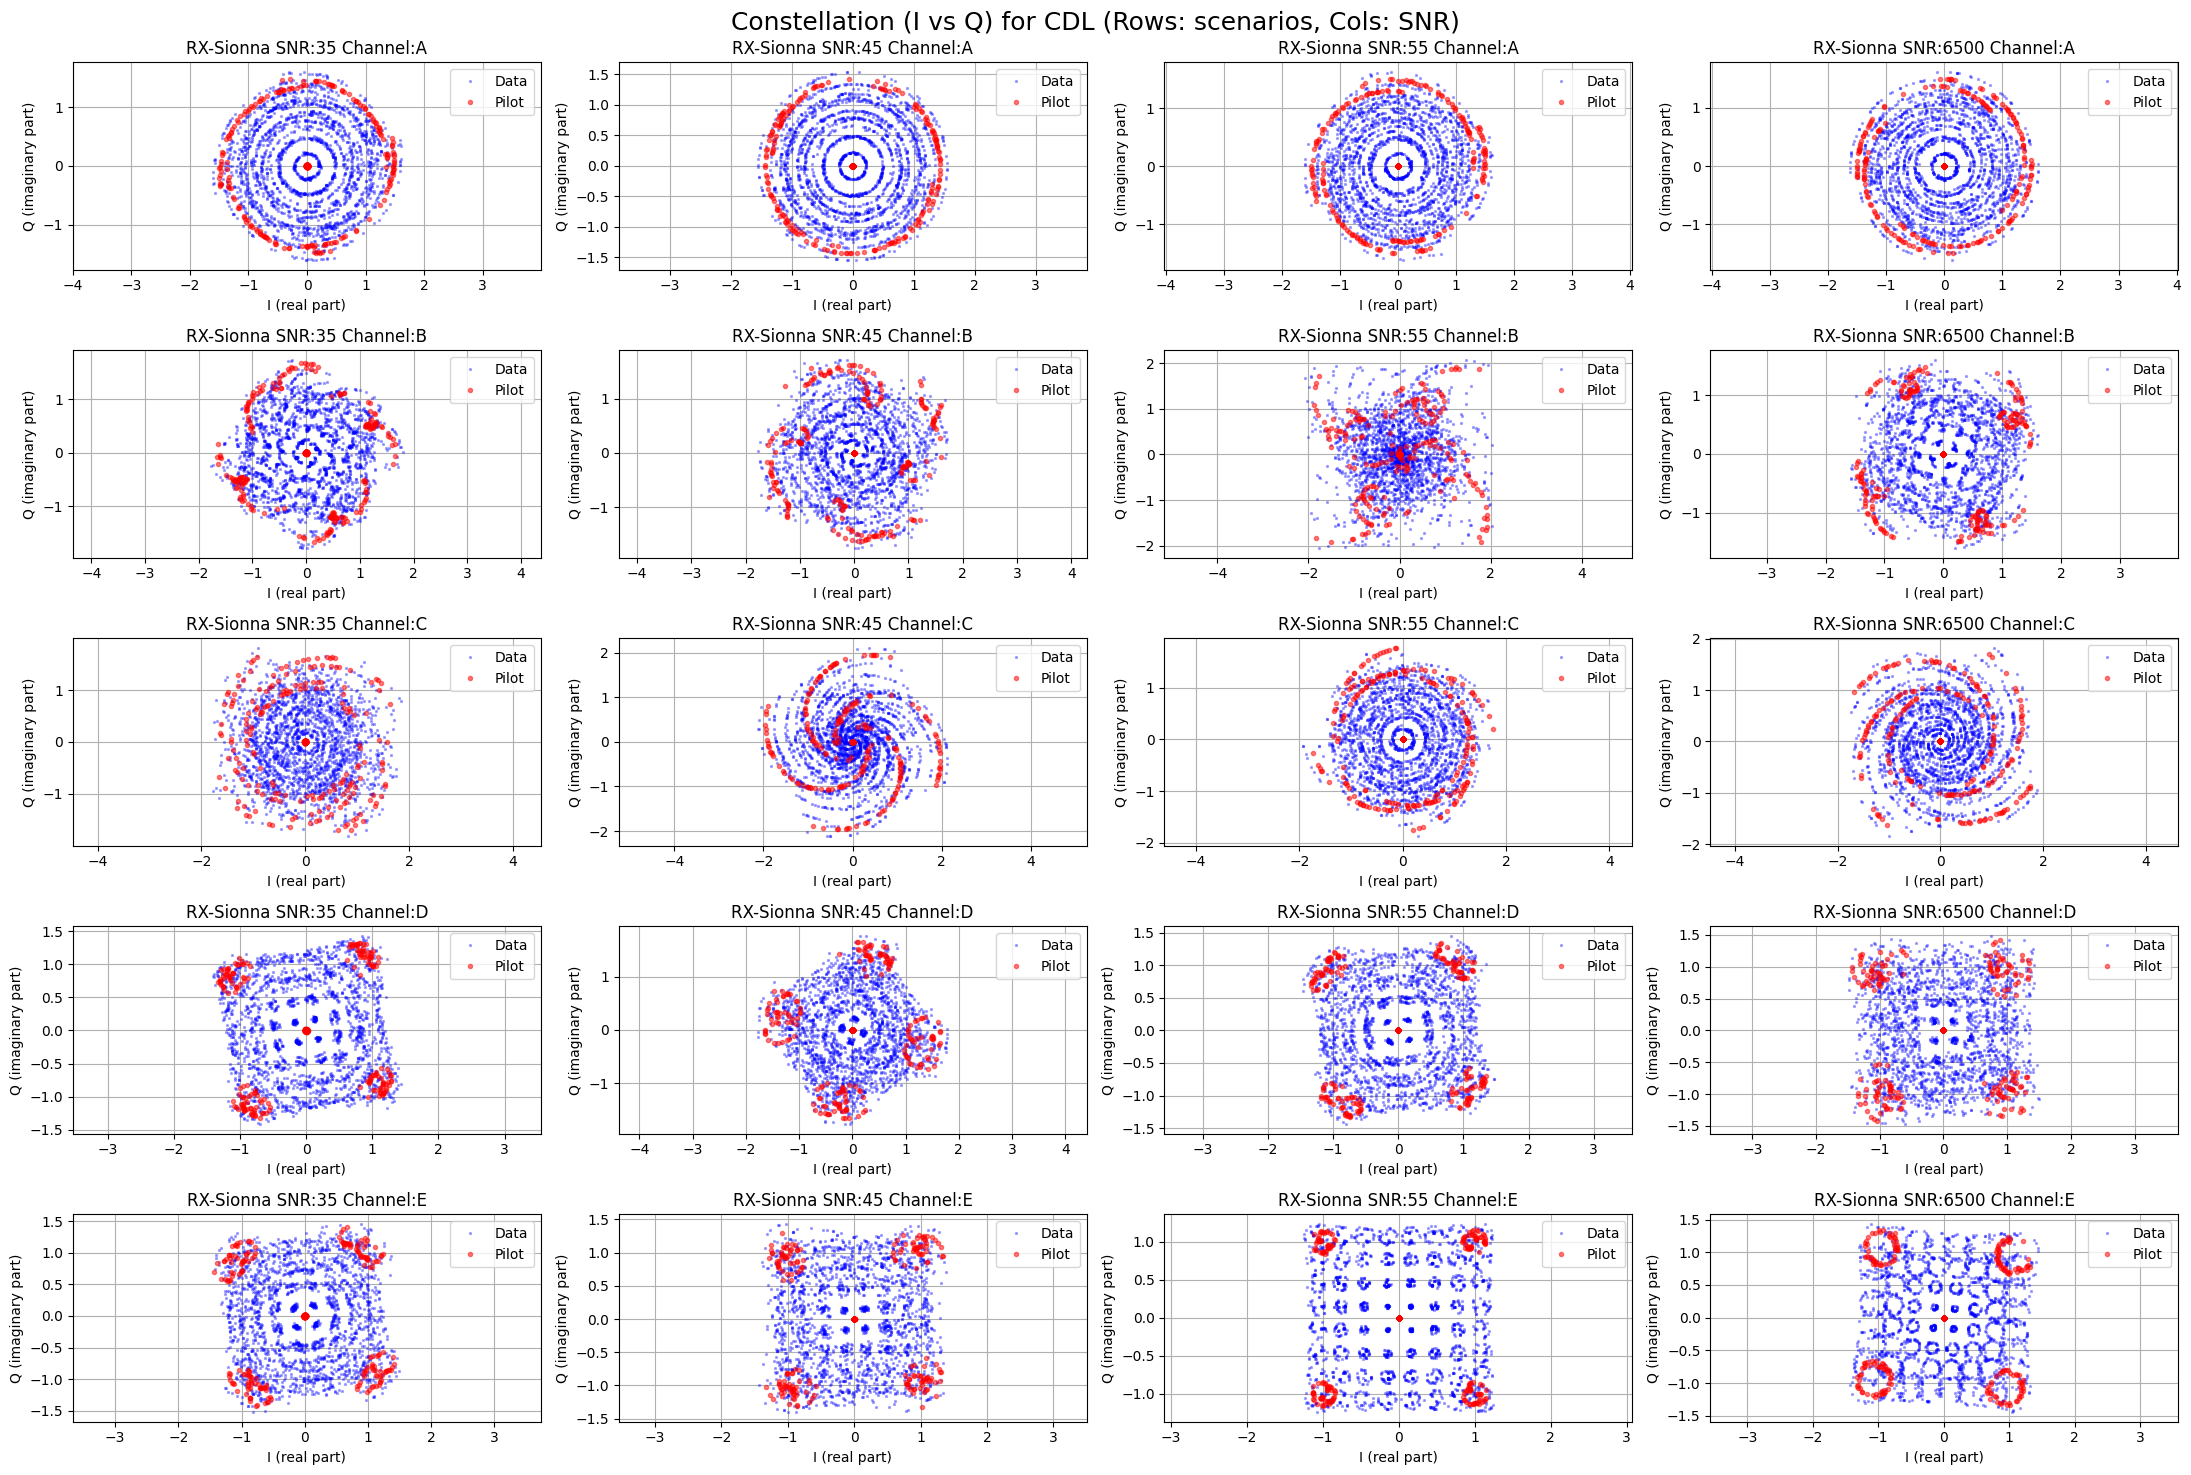

In [7]:
def plot_constellations(dataset, model_type, scenarios, ebno_values, pilot_symbols):
    fig, axes = plt.subplots(len(scenarios), len(ebno_values), figsize=(22, 15))
    for row, scenario in enumerate(scenarios):
        for col, ebno in enumerate(ebno_values):
            sample = next((d for d in dataset if d['scenario'] == scenario and d['ebno_db'] == ebno and d['model_type'] == model_type), None)
            ax = axes[row, col]
            if sample is not None:
                y = sample['y']
                y = y[0, 0, 0, :, :]  # shape (14, 192)
                re = y.real
                im = y.imag
                pilot_re = re[pilot_symbols, :].flatten()
                pilot_im = im[pilot_symbols, :].flatten()
                data_symbols = [i for i in range(y.shape[0]) if i not in pilot_symbols]
                data_re = re[data_symbols, :].flatten()
                data_im = im[data_symbols, :].flatten()
                ax.plot(data_re, data_im, '*', markersize=2, alpha=0.3, label='Data', color='blue')
                ax.plot(pilot_re, pilot_im, 'o', markersize=3, alpha=0.5, label='Pilot', color='red')
                ax.set_title(f"RX-Sionna SNR:{ebno} Channel:{scenario}", fontsize=12)
                ax.set_xlabel("I (real part)")
                ax.set_ylabel("Q (imaginary part)")
                ax.legend()
                # axis equal for me
                ax.axis('equal')
                # set x and y limits
                
                ax.grid(True)
            else:
                ax.axis('off')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    fig.suptitle(f"Constellation (I vs Q) for {model_type.upper()} (Rows: scenarios, Cols: SNR)", fontsize=18)
    plt.show()
# Plot for TDL (20 subplots)
plot_constellations(dataset_test_small, "tdl", scenarios, ebno_values_small, pilot_symbols)
# Plot for CDL (20 subplots)
plot_constellations(dataset_test_small, "cdl", scenarios, ebno_values_small, pilot_symbols)